[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/T8_monte_carlo/T8_monte_carlo.ipynb)

# T8 — Simulação de Monte Carlo

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · Tema T8**

Em vez de fórmulas, a simulação de Monte Carlo "vive" o sistema milhares de vezes no computador e conta em quantas ele sobreviveu. Este *notebook* mostra o método num sistema **inventado** de dois componentes, onde se pode confirmar o resultado com a fórmula.

**Como usar:** execute as células por ordem (Shift+Enter). As primeiras secções estão resolvidas, com dados da aula ou com exemplos inventados, para mostrar o método. A última secção, **A sua vez**, lê os dados da instalação e deixa pistas: o trabalho do grupo começa aí. O capítulo deste tema no documento de apoio explica cada passo.

## 1. A ideia, com dois componentes em paralelo

Dois componentes iguais em paralelo, cada um com tempo até à falha exponencial de MTBF 1000 h (valores inventados).

Uma simulação é uma "vida" do sistema:

1. sortear o tempo até à falha de cada componente;
2. determinar quando falha o sistema. Num **paralelo**, o sistema falha quando falha o **último** componente (o máximo dos tempos). Numa **série**, falha quando falha o **primeiro** (o mínimo).

Repetindo $N$ vezes, a fiabilidade para uma missão de duração $t$ é a proporção de vidas em que o sistema durou mais do que $t$.

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/"

def obter(ficheiro):
    """Vai buscar o ficheiro ao repositório. Se falhar, abre uma janela
    para o escolher no seu computador."""
    if not os.path.exists(ficheiro):
        try:
            urllib.request.urlretrieve(REPO + ficheiro, ficheiro)
        except Exception:
            from google.colab import files
            print("Escolha no seu computador o ficheiro", ficheiro)
            carregados = files.upload()
            if ficheiro not in carregados:               # veio com outro nome: renomeia
                os.rename(list(carregados)[0], ficheiro)
    return ficheiro

rng = np.random.default_rng(2026)            # semente fixa: os resultados repetem-se
N = 10_000
comp = stats.expon(scale=1000)

t1 = comp.rvs(size=N, random_state=rng)      # N tempos até à falha do componente 1
t2 = comp.rvs(size=N, random_state=rng)      # ... e do componente 2
t_sis = np.maximum(t1, t2)                   # paralelo: falha quando falha o último

print("Primeiras cinco vidas:")
print(pd.DataFrame({"comp. 1": t1[:5], "comp. 2": t2[:5], "sistema": t_sis[:5]}).round(0))

Primeiras cinco vidas:
   comp. 1  comp. 2  sistema
0    149.0   1241.0   1241.0
1   1266.0     68.0   1266.0
2    429.0    307.0    429.0
3    686.0    343.0    686.0
4    978.0    124.0    978.0


## 2. Validar: comparar com a fórmula

Para uma missão de 500 h, a fórmula do paralelo dá $R = 1 - (1 - e^{-500/1000})^2$. A simulação deve dar um valor próximo. **Valide sempre a simulação num caso em que sabe a resposta**, antes de a usar onde não sabe.

In [2]:
missao = 500
R_sim = (t_sis > missao).mean()
R_formula = 1 - (1 - comp.sf(missao)) ** 2
print(f"Simulação: {R_sim:.4f}     Fórmula: {R_formula:.4f}")

Simulação: 0.8437     Fórmula: 0.8452


## 3. Que incerteza tem a estimativa?

O resultado da simulação é uma proporção estimada com $N$ observações, e tem erro de amostragem. O erro-padrão é $\sqrt{\hat R(1-\hat R)/N}$, e um intervalo de confiança a 95 % é $\hat R \pm 1{,}96 \times$ erro-padrão.

Para reduzir o erro a metade, é preciso **quadruplicar** $N$.

In [3]:
linhas = []
for N in [100, 1_000, 10_000, 100_000]:
    a = comp.rvs(size=N, random_state=rng)
    b = comp.rvs(size=N, random_state=rng)
    R = (np.maximum(a, b) > missao).mean()
    ep = np.sqrt(R * (1 - R) / N)
    linhas.append({"N": N, "R simulado": R, "erro-padrão": ep, "IC inf": R - 1.96 * ep, "IC sup": R + 1.96 * ep})
print(f"Valor da fórmula: {R_formula:.4f}")
pd.DataFrame(linhas).set_index("N").round(4)

Valor da fórmula: 0.8452


,R simulado,erro-padrão,IC inf,IC sup
N,,,,
100,0.8600,0.0347,0.7920,0.9280
1000,0.8350,0.0117,0.8120,0.8580
10000,0.8403,0.0037,0.8331,0.8475
100000,0.8437,0.0011,0.8414,0.8459


## 4. A curva $R(t)$ completa

A grande vantagem: com os mesmos tempos simulados, obtém-se a fiabilidade para **qualquer** duração de missão, sem refazer as contas. O documento base trabalha com fiabilidades fixas; aqui a fiabilidade é uma curva.

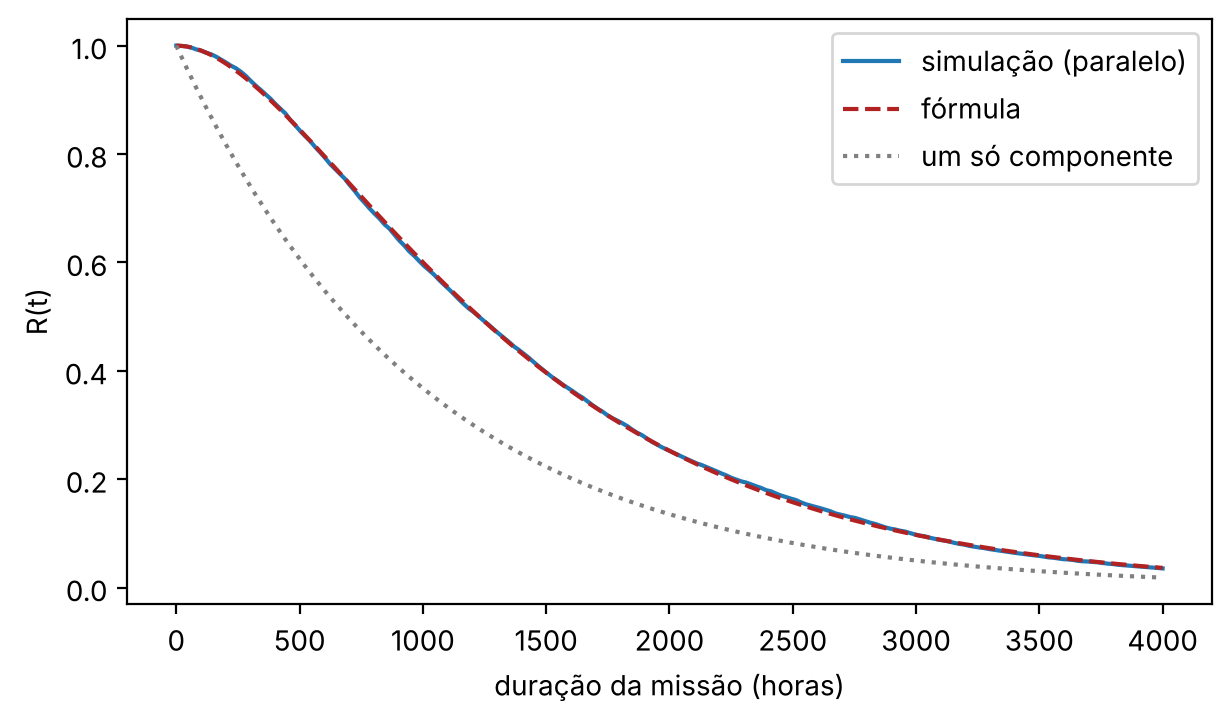

In [4]:
x = np.linspace(0, 4000, 200)
R_curva = [(t_sis > v).mean() for v in x]

plt.figure(figsize=(7, 3.8))
plt.plot(x, R_curva, label="simulação (paralelo)")
plt.plot(x, 1 - (1 - comp.sf(x)) ** 2, "--", color="firebrick", label="fórmula")
plt.plot(x, comp.sf(x), ":", color="gray", label="um só componente")
plt.xlabel("duração da missão (horas)"); plt.ylabel("R(t)"); plt.legend(); plt.show()

## 5. Outras distribuições

Qualquer distribuição do `scipy.stats` sorteia valores com `.rvs`. Exemplos com parâmetros inventados:

In [5]:
print(stats.norm(5000, 800).rvs(size=3, random_state=rng).round(0))                 # normal
print(stats.lognorm(s=0.5, scale=3000).rvs(size=3, random_state=rng).round(0))      # lognormal
print(stats.weibull_min(2.0, scale=4000).rvs(size=3, random_state=rng).round(0))    # Weibull

[3995. 4561. 4402.]
[1948. 5026. 1008.]
[2467. 2771. 4749.]


## 6. A sua vez

Pistas:

1. Precisa de um modelo para o tempo até à falha de cada um dos cinco componentes (secção 4 do documento de apoio, *notebook* `00_comum`, grupos dos temas T2 e T3).
2. Quantos tempos tem de sortear em cada vida? A instalação tem mais do que uma unidade de vários componentes (veja a figura na secção "Os dados da instalação").
3. Combine os tempos com `np.minimum` e `np.maximum`, de dentro para fora, tal como se reduz um diagrama de blocos: um ramo da rede falha quando falha o primeiro dos seus dois componentes; a rede falha quando falha o último ramo; e assim por diante.
4. Valide: para 2000 h, a simulação deve concordar com o cálculo analítico por diagrama de blocos (tema T6), dentro do intervalo de confiança.
5. Desenhe a curva $R(t)$ do sistema. Para que duração de missão a fiabilidade desce abaixo de 95 %?
6. Que número de simulações é necessário para que a incerteza não altere as conclusões?
7. Em cada vida simulada, registe **qual** foi o componente que fez falhar o sistema. O que conclui?
8. Uma normal pode sortear tempos negativos. Isso acontece com os seus parâmetros? Como tratar?

In [6]:
ensaios = pd.read_excel(obter("dados_fiabilidade.xlsx"), sheet_name="ensaios_vida")
N = 10_000

# Modelo de cada componente (a preencher pelo grupo), por exemplo:
# m_int = stats.expon(scale=...)
# t_int = m_int.rvs(size=(N, 3), random_state=rng)      # 3 interruptores em cada uma das N vidas
# t_trf = ...
# ramos = np.minimum(t_int, t_trf)                      # cada ramo: série interruptor + transformador
# rede  = ramos.max(axis=1)                             # três ramos em paralelo